# 04 — Time-varying transition probabilities

**Scope:** M1 constant transitions; M3 GPR; M4 VIX; M5 GPR and VIX. Every model has the same two-state Gaussian observation equation with switching means and variances. Only transition probabilities change. Estimation uses the 3,699 complete-case Brent returns from 2000–2015. No 2016-onward observations are read or used here.

Stage 03's coverage and ten-start M2 audits are prerequisites. The notebook stops if the gate file reports invalid coverage, unstable M1, invalid probabilities, or undocumented GARCH/M2 limitations. Stage 03 corrections are in the 03_correction outputs and the reproducible script in code/stage03_corrections.py.

## 1. Gate, data, and predictor timing

The raw Brent file has many early missing prices. In 2000–2002 there are 202, 194, and 194 nonmissing raw Brent prices, and the same counts of maximum usable returns. Complete-case merging removes only 5, 5, and 6 additional dates, respectively, because VIX is missing. Returns after missing prices span the prior observed-price interval; they are percentage log changes **over that interval**, not necessarily a one-calendar-day change. The training data retain a gap-days column and are used as-is for comparability with Stage 03. This irregular spacing is a modelling limitation.

The GPR input is exactly the previous calendar day's GPR observation; the daily GPR file includes weekends. VIX is the previous nonmissing VIX observation, which can be multiple calendar days earlier. Both precede the return's reference date. The historical GPR vintage can be revised and its reference date does not prove publication-time availability. These models are retrospective association models, not validated real-time prediction or causal estimates.

Only training means and population standard deviations (ddof=0) are used to standardize predictor columns. The original predictor values are preserved in the processed input and training summary output. An explicit column of ones supplies transition intercepts, as required by [statsmodels TVTP](https://www.statsmodels.org/stable/_modules/statsmodels/tsa/regime_switching/markov_switching.html). The [statsmodels TVTP example](https://www.statsmodels.org/stable/examples/notebooks/generated/markov_autoregression.html) documents the time-varying transition approach.

In [1]:
from pathlib import Path
import json,platform,warnings
import numpy as np,pandas as pd,statsmodels,scipy,matplotlib,matplotlib.pyplot as plt
from scipy.special import expit
from statsmodels.tsa.regime_switching.markov_regression import MarkovRegression
from IPython.display import display,Markdown

PROJECT=Path.cwd() if (Path.cwd()/"data"/"processed").is_dir() else Path.cwd().parent
DATA=PROJECT/"data"/"processed"; TABLES=PROJECT/"results"/"tables"
FIGURES=PROJECT/"results"/"figures"
source=DATA/"01_brent_complete_case.csv"
gate=TABLES/"03_correction_gate.json"
assert source.exists() and gate.exists(), "Complete Stage 03 audit before Stage 04"
g=json.loads(gate.read_text())
assert g["successful_starts"]>=8 and g["attempted_starts"]>=10
assert g["min_occupancy"]>.05 and g["loglikelihood_spread"]<.05
assert "unavailable_standard_errors" in g and "minimum_transition" in g
m1_gate=pd.read_csv(TABLES/"03_markov_stability.csv").query("model == 'M1'").iloc[0]
assert m1_gate.successful_starts==3 and m1_gate.loglikelihood_spread<.01
assert not m1_gate.near_boundary_transition and m1_gate.min_mean_smoothed_occupancy>.05
m1_probs=pd.read_csv(TABLES/"03_m1_probabilities.csv")
assert np.allclose(m1_probs[["filtered_low","filtered_high"]].sum(axis=1),1,atol=1e-6)
assert np.allclose(m1_probs[["smoothed_low","smoothed_high"]].sum(axis=1),1,atol=1e-6)
coverage=pd.read_csv(TABLES/"03_correction_annual_coverage.csv")
assert coverage.loc[coverage.year.isin([2000,2001,2002]),"complete_case_returns"].tolist()==[197,189,188]
assert coverage.loc[coverage.year.isin([2000,2001,2002]),"raw_nonmissing_prices"].tolist()==[202,194,194]
garch_check=pd.read_csv(TABLES/"03_correction_garch_comparison.csv")
assert set(garch_check.distribution)=={"normal","t"}
assert garch_check.near_unit_persistence.any()
assert (garch_check.residual_arch_lm_p10<.05).any()
df=pd.read_csv(source,nrows=3699,
               parse_dates=["date","previous_observed_date","vix_lag_source_date"])
required={"date","split","brent_return_pct","observation_gap_calendar_days",
          "gpr_lag1_calendar_day","vix_lag1_observation","vix_lag_source_date"}
assert required.issubset(df.columns)
assert len(df)==3699 and df.date.is_unique and df.date.is_monotonic_increasing
assert df.split.eq("train").all()
train=df.copy().reset_index(drop=True)
assert len(train)==3699 and train.date.max()<=pd.Timestamp("2015-12-31")
assert train[["brent_return_pct","gpr_lag1_calendar_day",
              "vix_lag1_observation"]].notna().all().all()
assert (train.vix_lag_source_date<train.date).all()
y=train.brent_return_pct.to_numpy(dtype=float)
dates=train.date
features={"gpr":train.gpr_lag1_calendar_day.to_numpy(dtype=float),
          "vix":train.vix_lag1_observation.to_numpy(dtype=float)}
scale={}
for name,x in features.items():
    mean=float(x.mean()); sd=float(x.std(ddof=0))
    assert np.isfinite(mean) and sd>0
    scale[name]={"mean_training":mean,"sd_training":sd,
                 "p10_training":float(np.quantile(x,.1)),
                 "p90_training":float(np.quantile(x,.9))}
    features[name]=(x-mean)/sd
pd.DataFrame.from_dict(scale,orient="index").rename_axis("predictor").to_csv(
    TABLES/"04_training_scaling.csv")
display(pd.DataFrame.from_dict(scale,orient="index").round(4))
display(pd.Series({"Python":platform.python_version(),"NumPy":np.__version__,
                   "pandas":pd.__version__,"statsmodels":statsmodels.__version__,
                   "SciPy":scipy.__version__,"Matplotlib":matplotlib.__version__},
                  name="version").to_frame())
print("PASS gate: input coverage, 10-start M2 audit, documented GARCH/M2 limitations.")

,mean_training,sd_training,p10_training,p90_training
gpr,105.6085,66.2483,52.7144,164.3038
vix,20.5981,8.9824,12.3900,31.1780


,version
Python,3.12.14
NumPy,2.5.4
pandas,3.0.1
statsmodels,0.15.0
SciPy,1.18.1
Matplotlib,3.11.2


PASS gate: input coverage, 10-start M2 audit, documented GARCH/M2 limitations.


## 2. M1, M3, M4, M5 estimation

The transition design is respectively intercept only (M1), intercept plus standardized GPR (M3), intercept plus standardized VIX (M4), and intercept plus both (M5). M1 is refitted on the exact common data. For each model, three independently seeded searches (41, 67, 103) use 8 EM iterations, 6 random-search repetitions of 8 iterations, and up to 300 optimizer iterations. All failed attempts and warnings are logged. A converged fit must have finite likelihood and positive state variances. The best valid likelihood is retained; a missing standard error is recorded as missing.

Statsmodels stores the time-varying transition tensor as [destination, origin, observation]. We transpose and reorder by estimated variance to report origin-row matrices. In a two-state model, coefficients for transition to numerical state 0 are logistic; for a low/high reordered matrix, scenarios are evaluated using the fitted model's own transition function to avoid sign or orientation mistakes. Filtered and smoothed probabilities are exported separately; smoothed values incorporate later training observations and are retrospective.

In [2]:
SEEDS=[41,67,103]
SETTINGS={"em_iter":8,"search_reps":6,"search_iter":8,"maxiter":300,"disp":False}
specs={"M1":[],"M3":["gpr"],"M4":["vix"],"M5":["gpr","vix"]}
fits={}; attempts=[]
for name,cols in specs.items():
    X=np.column_stack([np.ones(len(y))]+[features[c] for c in cols]) if cols else None
    model=MarkovRegression(y,k_regimes=2,trend="c",switching_trend=True,
                           switching_variance=True,exog_tvtp=X)
    successful=[]
    for seed in SEEDS:
        np.random.seed(seed)
        try:
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter("always")
                fit=model.fit(**SETTINGS)
            params=pd.Series(fit.params,index=fit.model.param_names)
            valid=bool(fit.mle_retvals.get("converged",False)
                       and np.isfinite(fit.llf) and np.isfinite(fit.params).all()
                       and all(params[f"sigma2[{i}]"]>0 for i in range(2)))
            attempts.append({"model":name,"seed":seed,"log_likelihood":fit.llf,
                             "converged_valid":valid,"warning_count":len(caught),
                             "warnings":" | ".join(f"{w.category.__name__}: {w.message}" for w in caught),
                             "error":""})
            if valid: successful.append((fit.llf,seed,fit))
        except Exception as exc:
            attempts.append({"model":name,"seed":seed,"log_likelihood":np.nan,
                             "converged_valid":False,"warning_count":0,
                             "warnings":"","error":repr(exc)})
    if not successful:
        raise RuntimeError(f"{name}: no valid converged solution; inspect attempt log")
    fits[name]={"best":max(successful,key=lambda z:z[0]),
                "spread":max(z[0] for z in successful)-min(z[0] for z in successful),
                "successes":len(successful),"columns":cols,"model":model}
attempt_table=pd.DataFrame(attempts)
display(attempt_table.round(5))
attempt_table.to_csv(TABLES/"04_fit_attempts.csv",index=False,float_format="%.10g")

,model,seed,log_likelihood,converged_valid,warning_count,warnings,error
0,M1,41,-8042.62572,True,0,,
1,M1,67,-8042.62572,True,0,,
2,M1,103,-8042.62571,True,0,,
3,M3,41,-8035.50888,True,0,,
4,M3,67,-8035.50887,True,0,,
5,M3,103,-8035.50887,True,0,,
6,M4,41,-8029.99711,True,0,,
7,M4,67,-8029.99711,True,0,,
8,M4,103,-8029.99711,True,0,,
9,M5,41,-8025.59062,True,0,,


## 3. State alignment, probability checks, and model comparison

State 0 is low volatility and state 1 high volatility **after** sorting by estimated variance; this can reverse numerical statsmodels labels. Every model is checked for probability bounds and normalization. Average occupancy is based on smoothed probabilities and is therefore a retrospective summary. AIC/BIC use identical observations but are in-sample criteria, not forecast scores.

In [3]:
summary_rows=[]; regime_rows=[]; transition_rows=[]; output={}
for name,info in fits.items():
    ll,seed,fit=info["best"]
    p=pd.Series(fit.params,index=fit.model.param_names)
    order=np.argsort([p[f"sigma2[{i}]"] for i in range(2)])
    raw=np.asarray(fit.regime_transition)
    assert raw.shape==(2,2,1 if name=="M1" else len(y))
    assert np.all(np.isfinite(raw)) and np.all((raw>=-1e-9)&(raw<=1+1e-9))
    assert np.allclose(raw.sum(axis=0),1,atol=1e-7)
    P=raw.transpose(2,1,0)[:,order][:,:,order]
    assert np.allclose(P.sum(axis=2),1,atol=1e-7)
    daily=P if P.shape[0]==len(y) else np.repeat(P,len(y),axis=0)
    pd.DataFrame({"date":dates,"low_to_low":daily[:,0,0],
                  "low_to_high":daily[:,0,1],"high_to_low":daily[:,1,0],
                  "high_to_high":daily[:,1,1]}).to_csv(
                      TABLES/f"04_{name.lower()}_daily_transitions.csv",
                      index=False,date_format="%Y-%m-%d")
    filtered=np.asarray(fit.filtered_marginal_probabilities)[:,order]
    smoothed=np.asarray(fit.smoothed_marginal_probabilities)[:,order]
    assert filtered.shape==smoothed.shape==(len(y),2)
    assert np.all(np.isfinite(filtered)) and np.all(np.isfinite(smoothed))
    assert np.all((filtered>=-1e-8)&(filtered<=1+1e-8))
    assert np.all((smoothed>=-1e-8)&(smoothed<=1+1e-8))
    assert np.allclose(filtered.sum(axis=1),1,atol=1e-6)
    assert np.allclose(smoothed.sum(axis=1),1,atol=1e-6)
    pd.DataFrame({"date":dates,"low":filtered[:,0],"high":filtered[:,1]}).to_csv(
        TABLES/f"04_{name.lower()}_filtered.csv",index=False,date_format="%Y-%m-%d")
    pd.DataFrame({"date":dates,"low":smoothed[:,0],"high":smoothed[:,1]}).to_csv(
        TABLES/f"04_{name.lower()}_smoothed.csv",index=False,date_format="%Y-%m-%d")
    se=np.asarray(fit.bse)
    pd.DataFrame({"parameter":p.index,"estimate":p.values,
                  "std_error":se}).to_csv(TABLES/f"04_{name.lower()}_parameters.csv",index=False)
    summary_rows.append({"model":name,"parameters":len(p),"observations":len(y),
                         "log_likelihood":ll,"aic":fit.aic,"bic":fit.bic,
                         "converged":True,"successful_starts":info["successes"],
                         "likelihood_spread":info["spread"],"chosen_seed":seed,
                         "missing_standard_errors":int(np.isnan(se).sum())})
    for rank,label in enumerate(["Low","High"]):
        original=int(order[rank])
        regime_rows.append({"model":name,"state":rank,"label":label,
                            "original_state":original,"mean_pct":p[f"const[{original}]"],
                            "variance_pct2":p[f"sigma2[{original}]"],
                            "sd_pct":np.sqrt(p[f"sigma2[{original}]"]),
                            "smoothed_occupancy":smoothed[:,rank].mean(),
                            "classified_days":int((smoothed.argmax(axis=1)==rank).sum())})
    for i,origin in enumerate(["Low","High"]):
        for j,destination in enumerate(["Low","High"]):
            transition_rows.append({"model":name,"origin":origin,
                                    "destination":destination,
                                    "mean_probability":P[:,i,j].mean(),
                                    "minimum_probability":P[:,i,j].min(),
                                    "maximum_probability":P[:,i,j].max()})
    output[name]={"fit":fit,"order":order,"P":P,
                  "filtered":filtered,"smoothed":smoothed}
comparison=pd.DataFrame(summary_rows)
regimes=pd.DataFrame(regime_rows)
transitions=pd.DataFrame(transition_rows)
display(comparison.round(4));display(regimes.round(4));display(transitions.round(4))
comparison.to_csv(TABLES/"04_model_comparison.csv",index=False)
regimes.to_csv(TABLES/"04_regime_summary.csv",index=False)
transitions.to_csv(TABLES/"04_average_transitions.csv",index=False)

,model,parameters,observations,log_likelihood,aic,bic,converged,successful_starts,likelihood_spread,chosen_seed,missing_standard_errors
0,M1,6,3699,-8042.6257,16097.2514,16134.5463,True,3,0.0,103,0
1,M3,8,3699,-8035.5089,16087.0177,16136.7443,True,3,0.0,103,0
2,M4,8,3699,-8029.9971,16075.9942,16125.7208,True,3,0.0,41,0
3,M5,10,3699,-8025.5906,16071.1812,16133.3394,True,3,0.0,41,0


,model,state,label,original_state,mean_pct,variance_pct2,sd_pct,smoothed_occupancy,classified_days
0,M1,0,Low,0,0.1224,2.4795,1.5746,0.6819,2585
1,M1,1,High,1,-0.2325,11.8992,3.4495,0.3181,1114
2,M3,0,Low,0,0.1150,2.7540,1.6595,0.7409,2812
3,M3,1,High,1,-0.2923,13.2438,3.6392,0.2591,887
4,M4,0,Low,0,0.1053,2.5908,1.6096,0.7302,2801
5,M4,1,High,1,-0.2498,13.2927,3.6459,0.2698,898
6,M5,0,Low,0,0.1094,2.6649,1.6325,0.7406,2837
7,M5,1,High,1,-0.2758,13.4961,3.6737,0.2594,862


,model,origin,destination,mean_probability,minimum_probability,maximum_probability
0,M1,Low,Low,0.9734,0.9734,0.9734
1,M1,Low,High,0.0266,0.0266,0.0266
2,M1,High,Low,0.0564,0.0564,0.0564
3,M1,High,High,0.9436,0.9436,0.9436
4,M3,Low,Low,0.9715,0.0001,0.9957
5,M3,Low,High,0.0285,0.0043,0.9999
6,M3,High,Low,0.0598,0.0270,0.9808
7,M3,High,High,0.9402,0.0192,0.9730
8,M4,Low,Low,0.9658,0.9611,0.9842
9,M4,Low,High,0.0342,0.0158,0.0389


## 4. Predictor scenarios

For each fitted model, we evaluate the transition function at training-sample predictor 10th and 90th percentiles. In M5, one predictor varies while the other is held at its training median; low/low and high/high combinations are also shown. These are **conditional model-implied scenarios**, not historical forecast results, causal effects, or marginal effects on observed state labels. Coefficients refer to transitions into the original numerical state 0; the exported scenario table reports economically ordered low/high origins and destinations.

,model,scenario,gpr_z,vix_z,low_to_low,low_to_high,high_to_low,high_to_high
0,M3,gpr_p10_other_median,-0.7984,NaN,0.9919,0.0081,0.0372,0.9628
1,M3,gpr_p90_other_median,0.8860,NaN,0.9621,0.0379,0.0798,0.9202
2,M4,vix_p10_other_median,NaN,-0.9138,0.9623,0.0377,0.2527,0.7473
3,M4,vix_p90_other_median,NaN,1.1778,0.9702,0.0298,0.0281,0.9719
4,M5,gpr_p10_other_median,-0.7984,-0.2492,0.9837,0.0163,0.0982,0.9018
5,M5,gpr_p90_other_median,0.8860,-0.2492,0.9481,0.0519,0.1493,0.8507
6,M5,vix_p10_other_median,-0.2052,-0.9138,0.9705,0.0295,0.2172,0.7828
7,M5,vix_p90_other_median,-0.2052,1.1778,0.9834,0.0166,0.0242,0.9758
8,M5,both_p10,-0.7984,-0.9138,0.9804,0.0196,0.1900,0.8100
9,M5,both_p90,0.8860,1.1778,0.9647,0.0353,0.0327,0.9673


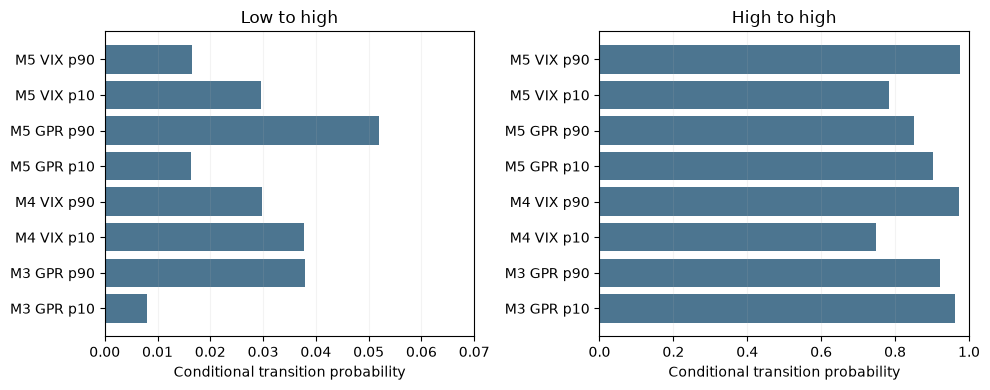

In [4]:
scenario_rows=[]
for name,info in fits.items():
    if name=="M1": continue
    model=info["model"]; fit=output[name]["fit"]; order=output[name]["order"]
    cols=info["columns"]
    scenario_dict={}
    for focal in cols:
        for q,label in [(.1,"p10"),(.9,"p90")]:
            values={c:float(np.quantile(features[c],.5)) for c in cols}
            values[focal]=float(np.quantile(features[focal],q))
            scenario_dict[f"{focal}_{label}_other_median"]=values
    if name=="M5":
        for q,label in [(.1,"both_p10"),(.9,"both_p90")]:
            scenario_dict[label]={c:float(np.quantile(features[c],q)) for c in cols}
    for label,values in scenario_dict.items():
        x=np.array([[1.0]+[values[c] for c in cols]])
        raw=np.asarray(model.regime_transition_matrix(fit.params,exog_tvtp=x))
        assert raw.shape==(2,2,1)
        P=raw[:,:,0].T[np.ix_(order,order)]
        assert np.allclose(P.sum(axis=1),1,atol=1e-9)
        scenario_rows.append({"model":name,"scenario":label,
                              "gpr_z":values.get("gpr",np.nan),
                              "vix_z":values.get("vix",np.nan),
                              "low_to_low":P[0,0],"low_to_high":P[0,1],
                              "high_to_low":P[1,0],"high_to_high":P[1,1]})
scenarios=pd.DataFrame(scenario_rows)
display(scenarios.round(4))
scenarios.to_csv(TABLES/"04_transition_scenarios.csv",index=False)
fig,axes=plt.subplots(1,2,figsize=(10,4))
for ax,column,title in [(axes[0],"low_to_high","Low to high"),
                        (axes[1],"high_to_high","High to high")]:
    sub=scenarios.loc[scenarios.scenario.isin(
        ["gpr_p10_other_median","gpr_p90_other_median",
         "vix_p10_other_median","vix_p90_other_median"])]
    labels=[f"{r.model} {r.scenario.split('_')[0].upper()} {r.scenario.split('_')[1]}"
            for r in sub.itertuples()]
    positions=np.arange(len(labels))
    ax.barh(positions,sub[column].to_numpy(),color="#4c7590")
    ax.set_yticks(positions,labels)
    ax.set(xlim=(0,.07) if column=="low_to_high" else (0,1),
           xlabel="Conditional transition probability",title=title)
    ax.grid(axis="x",alpha=.15)
fig.tight_layout();fig.savefig(FIGURES/"04_transition_scenarios.png",bbox_inches="tight")
plt.show()

## 5. Probability figures and interpretation

Filtered probabilities use information through the current date, including its return; they are not one-step-ahead forecasts. Smoothed probabilities incorporate subsequent training returns and are intended only for retrospective analysis. We plot both types separately and make no out-of-sample performance claim. The correlation between historical revised GPR and returns is not causal evidence.

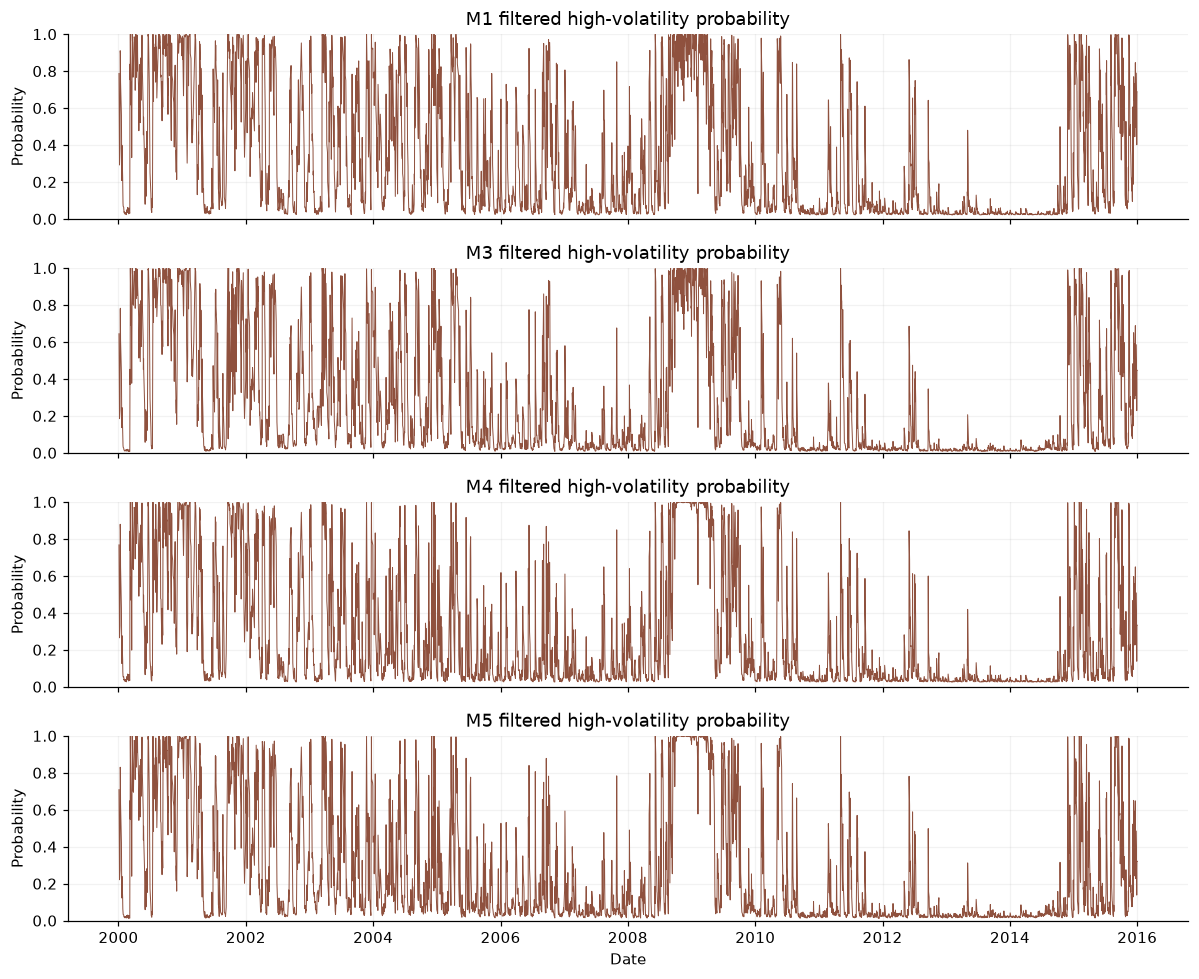

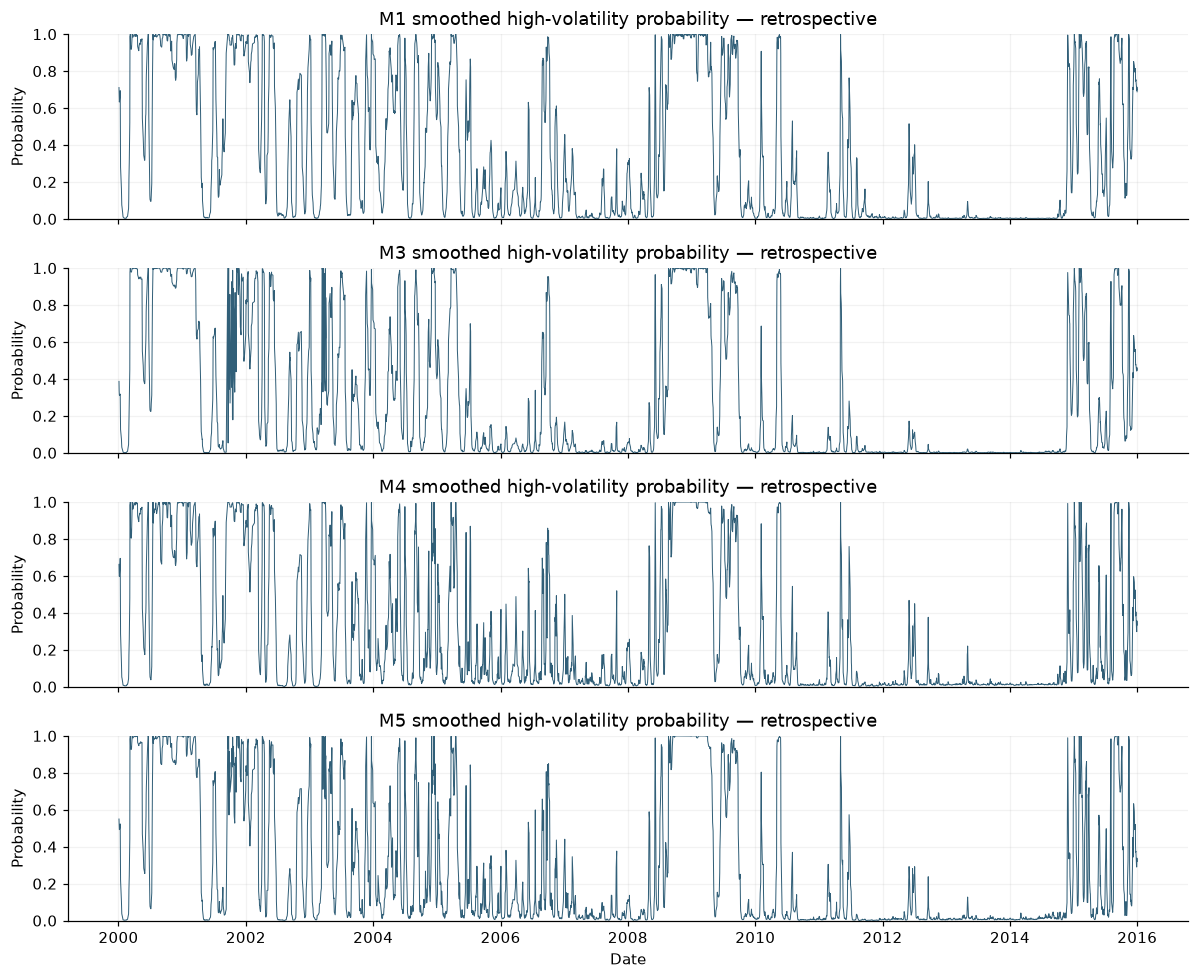


### Stage 04 findings

**Pass gate:** The Stage 03 coverage, M1 stability, probability normalization, ten-start M2 occupancy and likelihood-spread checks passed. The GARCH near-unit persistence and residual ARCH effects, plus M2 boundary and standard-error limitations, remain documented rather than treated as gate failures.

M1 constant-transition training log likelihood is -8042.63. The smallest in-sample AIC is M5 (16071.18); the smallest BIC is M4 (16125.72). This is model-development evidence only, not out-of-sample predictive performance. All four models use 3,699 identical training observations.

Missing standard errors: none. Likelihood spreads above 0.05 across converged starts: none. Interpret transition coefficients in their numerical-state parameterization and use the reordered scenario table for economic low/high labels. Changes in model-implied probabilities at different predictor levels are associations under the fitted model. Historical GPR release timing remains unresolved.


Stage 04 tables: 22 figures: 3


In [5]:
plt.rcParams.update({"figure.dpi":110,"savefig.dpi":180,"font.size":10,
                     "axes.spines.top":False,"axes.spines.right":False})
fig,axes=plt.subplots(4,1,figsize=(11,9),sharex=True)
for ax,(name,item) in zip(axes,output.items()):
    ax.plot(dates,item["filtered"][:,1],lw=.65,label=name,color="#8f513e")
    ax.set(ylabel="Probability",ylim=(0,1),title=f"{name} filtered high-volatility probability")
    ax.grid(alpha=.16)
axes[-1].set_xlabel("Date")
fig.tight_layout();fig.savefig(FIGURES/"04_filtered_high_probabilities.png",bbox_inches="tight")
plt.show()
fig,axes=plt.subplots(4,1,figsize=(11,9),sharex=True)
for ax,(name,item) in zip(axes,output.items()):
    ax.plot(dates,item["smoothed"][:,1],lw=.65,label=name,color="#315f78")
    ax.set(ylabel="Probability",ylim=(0,1),title=f"{name} smoothed high-volatility probability — retrospective")
    ax.grid(alpha=.16)
axes[-1].set_xlabel("Date")
fig.tight_layout();fig.savefig(FIGURES/"04_smoothed_high_probabilities.png",bbox_inches="tight")
plt.show()

base=comparison.loc[comparison.model.eq("M1")].iloc[0]
best=comparison.loc[comparison.bic.idxmin()]
best_aic=comparison.loc[comparison.aic.idxmin()]
bad_se=comparison.loc[comparison.missing_standard_errors.gt(0),"model"].tolist()
unstable=comparison.loc[comparison.likelihood_spread.gt(.05),"model"].tolist()
message=f'''
### Stage 04 findings

**Pass gate:** The Stage 03 coverage, M1 stability, probability normalization, ten-start M2 occupancy and likelihood-spread checks passed. The GARCH near-unit persistence and residual ARCH effects, plus M2 boundary and standard-error limitations, remain documented rather than treated as gate failures.

M1 constant-transition training log likelihood is {base.log_likelihood:.2f}. The smallest in-sample AIC is {best_aic.model} ({best_aic.aic:.2f}); the smallest BIC is {best.model} ({best.bic:.2f}). This is model-development evidence only, not out-of-sample predictive performance. All four models use {len(y):,} identical training observations.

Missing standard errors: {bad_se if bad_se else "none"}. Likelihood spreads above 0.05 across converged starts: {unstable if unstable else "none"}. Interpret transition coefficients in their numerical-state parameterization and use the reordered scenario table for economic low/high labels. Changes in model-implied probabilities at different predictor levels are associations under the fitted model. Historical GPR release timing remains unresolved.
'''
display(Markdown(message))
print("Stage 04 tables:",len(list(TABLES.glob("04_*.csv"))),
      "figures:",len(list(FIGURES.glob("04_*.png"))))